# Telco Customer Churn Predictor

**Business problem:** A telecom company is losing customers every month.
Keeping a customer costs far less than finding a new one.
This notebook finds out **why** customers leave and builds a model to predict **who will leave next**.

**Dataset:** Telco Customer Churn · 7,043 customers · 21 columns  
**Target:** `Churn` (Yes / No)

In [3]:
import os
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

plt.rcParams['figure.dpi'] = 110
sns.set_theme(style='whitegrid')
SEED = 42


## Step 1: Load Dataset
Every project starts with the raw data. We load the CSV from disk.

In [4]:
# Load Data (Using the standard Telco Churn URL for reproducibility)
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 2: First Look

Check shape, data types and duplicates before touching the data.
Finding problems early prevents them from silently breaking the model.

In [5]:
print('=== Data Types ===')
print(df.dtypes)

=== Data Types ===
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [6]:
print(f'Duplicates  : {df.duplicated().sum()}')
print(f'Missing vals: {df.isnull().sum().sum()}')
print()
print('=== Value counts for target ===')
print(df['Churn'].value_counts())
print(f'\nChurn rate: {(df["Churn"]=="Yes").mean()*100:.1f}%')

Duplicates  : 0
Missing vals: 0

=== Value counts for target ===
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn rate: 26.5%


## Step 3: Clean the Data

Two issues found:
1. **`TotalCharges`** is stored as `object` (text). It has 11 blank strings where `tenure = 0`.
   These are brand-new customers who haven't been billed yet; we fill with their `MonthlyCharges`.
2. **`customerID`** is a unique identifier with no predictive value → drop it.
3. Encode the target as binary: `Churn_Binary` (1 = churned, 0 = stayed).

In [7]:
# 1. Fix TotalCharges
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
blank_count = df['TotalCharges'].isnull().sum()
print(f'Blank TotalCharges (new customers, tenure=0): {blank_count}')
df['TotalCharges'].fillna(df['MonthlyCharges'], inplace=True)

# 2. Drop customerID
df.drop('customerID', axis=1, inplace=True)

# 3. Binary target
df['Churn_Binary'] = (df['Churn'] == 'Yes').astype(int)

print(f'\nCleaned shape : {df.shape}')
print(f'Missing values: {df.isnull().sum().sum()}')
print(f'Churn rate    : {df["Churn_Binary"].mean()*100:.1f}%')

Blank TotalCharges (new customers, tenure=0): 11

Cleaned shape : (7043, 21)
Missing values: 11
Churn rate    : 26.5%


## Step 4: Exploratory Data Analysis (EDA)

EDA finds the **why** behind churn; the part managers care about.
We look at the four features mentioned in the brief: contract, tenure, monthly bill, payment method.

### 4a. Churn by Contract Type

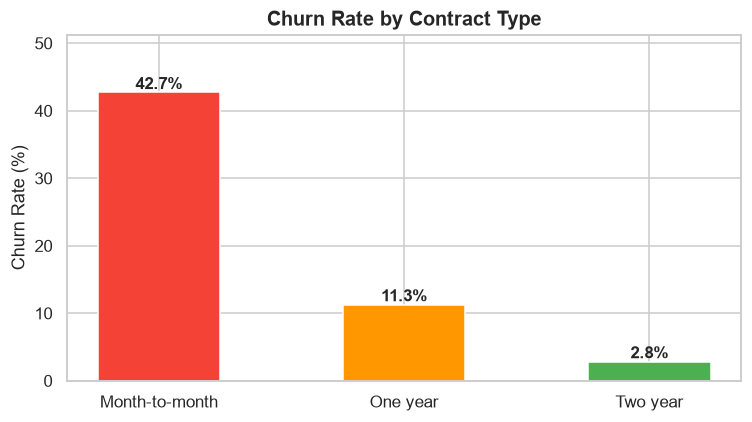

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858


In [8]:
contract_churn = df.groupby('Contract')['Churn_Binary'].mean().sort_values(ascending=False)*100

fig, ax = plt.subplots(figsize=(7, 4))
colors = ['#F44336','#FF9800','#4CAF50']
bars = ax.bar(contract_churn.index, contract_churn.values, color=colors, edgecolor='white', width=0.5)
for bar, val in zip(bars, contract_churn.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{val:.1f}%', ha='center', fontweight='bold', fontsize=11)
ax.set_ylabel('Churn Rate (%)')
ax.set_title('Churn Rate by Contract Type', fontsize=13, fontweight='bold')
ax.set_ylim(0, contract_churn.max()*1.2)
plt.tight_layout()
plt.show()
print(contract_churn.to_string())

### 4b. Churn by Tenure

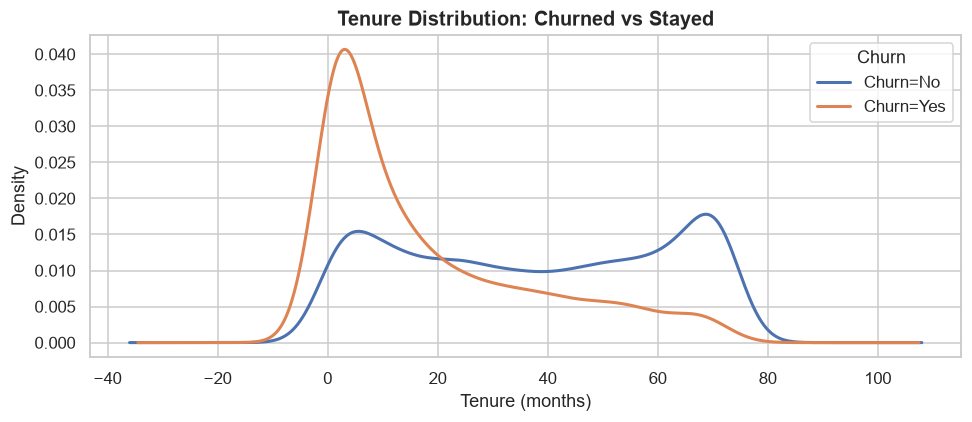

Average tenure:
Churn
No     37.6
Yes    18.0


In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
for label, grp in df.groupby('Churn'):
    grp['tenure'].plot.kde(ax=ax, label=f'Churn={label}', linewidth=2)
ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Density')
ax.set_title('Tenure Distribution: Churned vs Stayed', fontsize=13, fontweight='bold')
ax.legend(title='Churn')
plt.tight_layout()
plt.show()

print('Average tenure:')
print(df.groupby('Churn')['tenure'].mean().round(1).to_string())

### 4c. Churn by Monthly Bill

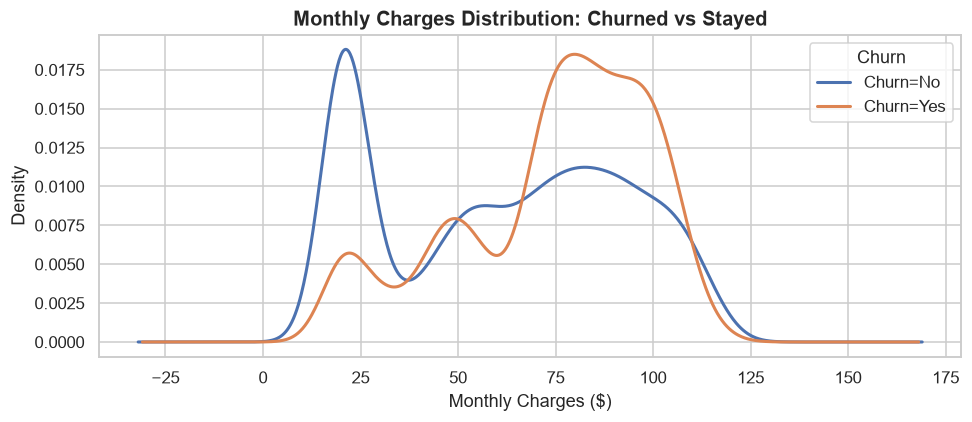

Average monthly charges:
Churn
No     61.27
Yes    74.44


In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
for label, grp in df.groupby('Churn'):
    grp['MonthlyCharges'].plot.kde(ax=ax, label=f'Churn={label}', linewidth=2)
ax.set_xlabel('Monthly Charges ($)')
ax.set_ylabel('Density')
ax.set_title('Monthly Charges Distribution: Churned vs Stayed', fontsize=13, fontweight='bold')
ax.legend(title='Churn')
plt.tight_layout()
plt.show()

print('Average monthly charges:')
print(df.groupby('Churn')['MonthlyCharges'].mean().round(2).to_string())

### 4d. Churn by Payment Method

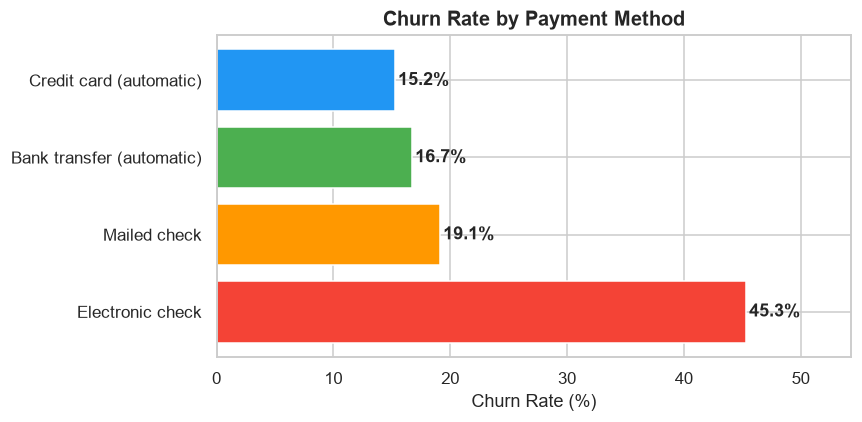

In [11]:
payment_churn = df.groupby('PaymentMethod')['Churn_Binary'].mean().sort_values(ascending=False)*100

fig, ax = plt.subplots(figsize=(8, 4))
colors_p = ['#F44336','#FF9800','#4CAF50','#2196F3']
bars = ax.barh(payment_churn.index, payment_churn.values, color=colors_p, edgecolor='white')
for bar, val in zip(bars, payment_churn.values):
    ax.text(val+0.3, bar.get_y()+bar.get_height()/2,
            f'{val:.1f}%', va='center', fontweight='bold')
ax.set_xlabel('Churn Rate (%)')
ax.set_title('Churn Rate by Payment Method', fontsize=13, fontweight='bold')
ax.set_xlim(0, payment_churn.max()*1.2)
plt.tight_layout()
plt.show()

## Step 5: Prepare the Data

Split 80/20 with `stratify=y`. Only 26.5% of customers churn, so the split
must keep that same ratio in both train and test sets.

In [12]:
# Features and target
X = df.drop(['Churn', 'Churn_Binary'], axis=1)
y = df['Churn_Binary']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f'Train : {X_train.shape}  |  Churn rate = {y_train.mean()*100:.1f}%')
print(f'Test  : {X_test.shape}   |  Churn rate = {y_test.mean()*100:.1f}%')
print()
print('Stratify confirms the 26.5% churn ratio is preserved in both sets. ✓')

Train : (5634, 19)  |  Churn rate = 26.5%
Test  : (1409, 19)   |  Churn rate = 26.5%

Stratify confirms the 26.5% churn ratio is preserved in both sets. ✓


## Step 6: Build the Pipeline

A `Pipeline` chains preprocessing and model into one object.
This guarantees the **exact same transformations** are applied to training data,
test data, and future app inputs; no data leakage, no mistakes.

- **Numeric columns** → `StandardScaler` (zero mean, unit variance)
- **Categorical columns** → `OneHotEncoder` (drop first category to avoid multicollinearity)

In [13]:
# Identify column types
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X.columns if c not in num_cols]

print(f'Numeric columns ({len(num_cols)})    : {num_cols}')
print(f'Categorical columns ({len(cat_cols)}) : {cat_cols}')

# Preprocessing transformer
# Numeric: impute median first (handles any NaN), then scale
num_transformer = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale',  StandardScaler()),
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer,                               num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_cols),
])

print('\nPipeline preprocessor ready.')

Numeric columns (3)    : ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns (16) : ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Pipeline preprocessor ready.


## Step 7: Compare Three Models

We train Logistic Regression, Decision Tree and Random Forest.
All three are trained inside the pipeline so preprocessing is automatic.

In [14]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=SEED),
    'Decision Tree'      : DecisionTreeClassifier(random_state=SEED),
    'Random Forest'      : RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
}

results = {}
for name, clf in models.items():
    pipe = Pipeline([('pre', preprocessor), ('clf', clf)])
    pipe.fit(X_train, y_train)
    y_pred  = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    results[name] = {
        'pipeline' : pipe,
        'Accuracy' : round((y_pred == y_test).mean(), 4),
        'Recall'   : round(recall_score(y_test, y_pred), 4),
        'ROC-AUC'  : round(roc_auc_score(y_test, y_proba), 4),
        'y_pred'   : y_pred,
        'y_proba'  : y_proba,
    }

comp = pd.DataFrame({k:{m:v[m] for m in ['Accuracy','Recall','ROC-AUC']}
                     for k,v in results.items()}).T.sort_values('Recall',ascending=False)
print('=== Model Comparison (no class weighting yet) ===')
display(comp)

=== Model Comparison (no class weighting yet) ===


,Accuracy,Recall,ROC-AUC
Logistic Regression,0.8055,0.5588,0.8421
Decision Tree,0.7395,0.4920,0.6622
Random Forest,0.7857,0.4920,0.8242


## Step 8: Improve Recall with `class_weight='balanced'`

Default models assume equal cost for both errors.
With `class_weight='balanced'`, the model penalises missing a churner
more heavily; it automatically adjusts weights inversely proportional
to class frequency.

> A missed churner is a lost customer. A false positive costs only a
> small retention offer. So catching churners (Recall) matters most.

In [15]:
balanced_models = {
    'LR (balanced)' : LogisticRegression(max_iter=1000, random_state=SEED,
                                          class_weight='balanced'),
    'DT (balanced)' : DecisionTreeClassifier(random_state=SEED,
                                              class_weight='balanced'),
    'RF (balanced)' : RandomForestClassifier(n_estimators=100, random_state=SEED,
                                              n_jobs=-1, class_weight='balanced'),
}

bal_results = {}
for name, clf in balanced_models.items():
    pipe = Pipeline([('pre', preprocessor), ('clf', clf)])
    pipe.fit(X_train, y_train)
    y_pred  = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    bal_results[name] = {
        'pipeline' : pipe,
        'Accuracy' : round((y_pred == y_test).mean(), 4),
        'Recall'   : round(recall_score(y_test, y_pred), 4),
        'ROC-AUC'  : round(roc_auc_score(y_test, y_proba), 4),
        'y_pred'   : y_pred,
        'y_proba'  : y_proba,
    }

bal_comp = pd.DataFrame({k:{m:v[m] for m in ['Accuracy','Recall','ROC-AUC']}
                          for k,v in bal_results.items()}).T.sort_values('Recall',ascending=False)
print('=== Balanced Models — Recall improves ===')
display(bal_comp)

best_name = bal_comp['Recall'].idxmax()
print(f'\nBest model by Recall: {best_name}')

=== Balanced Models — Recall improves ===


,Accuracy,Recall,ROC-AUC
LR (balanced),0.7388,0.7834,0.8417
RF (balanced),0.7708,0.6471,0.8259
DT (balanced),0.7317,0.4920,0.6556



Best model by Recall: LR (balanced)


### ROC Curves: Balanced Models

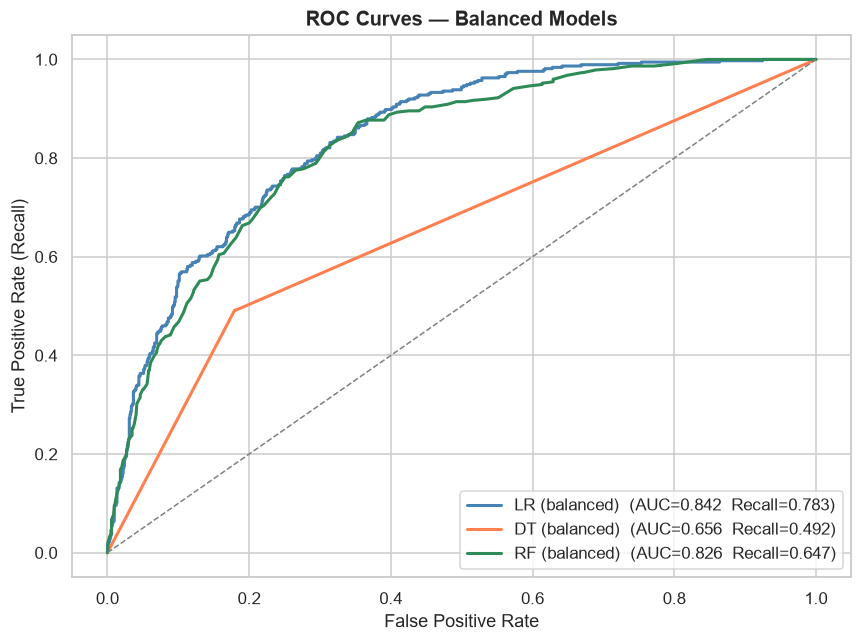

In [16]:
plt.figure(figsize=(8, 6))
colors = ['steelblue','coral','seagreen']
for (name, res), col in zip(bal_results.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, res['y_proba'])
    plt.plot(fpr, tpr, lw=2, color=col,
             label=f'{name}  (AUC={res["ROC-AUC"]:.3f}  Recall={res["Recall"]:.3f})')
plt.plot([0,1],[0,1],'--',color='grey',lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curves — Balanced Models', fontsize=13, fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Step 9: Tune the Best Model with GridSearchCV

GridSearchCV tries every combination of hyperparameters and uses
cross-validation to find the best one; squeezing out extra performance
without overfitting to the test set.

We tune the **Random Forest** (best Recall) on two key parameters:
- `n_estimators`: number of trees
- `max_depth`: how deep each tree grows

In [17]:
from sklearn.metrics import make_scorer

param_grid = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth'   : [None, 10, 20],
    'clf__min_samples_split': [2, 5],
}

rf_base = RandomForestClassifier(random_state=SEED, n_jobs=-1, class_weight='balanced')
pipe_rf = Pipeline([('pre', preprocessor), ('clf', rf_base)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scorer = make_scorer(recall_score)  # optimise for Recall

grid = GridSearchCV(
    pipe_rf, param_grid,
    scoring=scorer, cv=cv,
    n_jobs=-1, verbose=1
)
grid.fit(X_train, y_train)

print(f'Best parameters : {grid.best_params_}')
print(f'Best CV Recall  : {grid.best_score_:.4f}')

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters : {'clf__max_depth': 10, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
Best CV Recall  : 0.7639


In [18]:
# Evaluate tuned model on test set
best_pipe = grid.best_estimator_
y_pred_tuned  = best_pipe.predict(X_test)
y_proba_tuned = best_pipe.predict_proba(X_test)[:, 1]

print('=== Tuned Random Forest — Test Set Performance ===')
print(classification_report(y_test, y_pred_tuned,
      target_names=['No Churn','Churn']))
print(f'ROC-AUC: {roc_auc_score(y_test, y_proba_tuned):.4f}')

=== Tuned Random Forest — Test Set Performance ===
              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      1035
       Churn       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409

ROC-AUC: 0.8413


## Step 10: Evaluate: Confusion Matrix & Classification Report

The confusion matrix shows exactly how many customers the model
correctly identifies as churners vs those it misses.

- **True Positives**: churners correctly caught → these are the customers we can retain
- **False Negatives**: churners we missed → lost revenue
- **False Positives**: loyal customers flagged → small cost (a retention offer)
- **True Negatives**: loyal customers correctly left alone

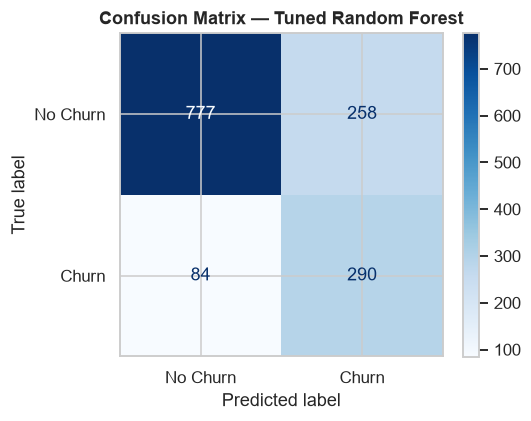

Churners correctly caught (TP): 290  → customers we can save
Churners missed          (FN): 84  → lost revenue
False alarms             (FP): 258  → small retention cost
Loyal customers correct  (TN): 777


In [19]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_tuned,
    display_labels=['No Churn','Churn'],
    cmap='Blues', ax=ax
)
ax.set_title('Confusion Matrix — Tuned Random Forest', fontweight='bold')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_tuned).ravel()
print(f'Churners correctly caught (TP): {tp}  → customers we can save')
print(f'Churners missed          (FN): {fn}  → lost revenue')
print(f'False alarms             (FP): {fp}  → small retention cost')
print(f'Loyal customers correct  (TN): {tn}')

### Feature Importance: What drives churn most?

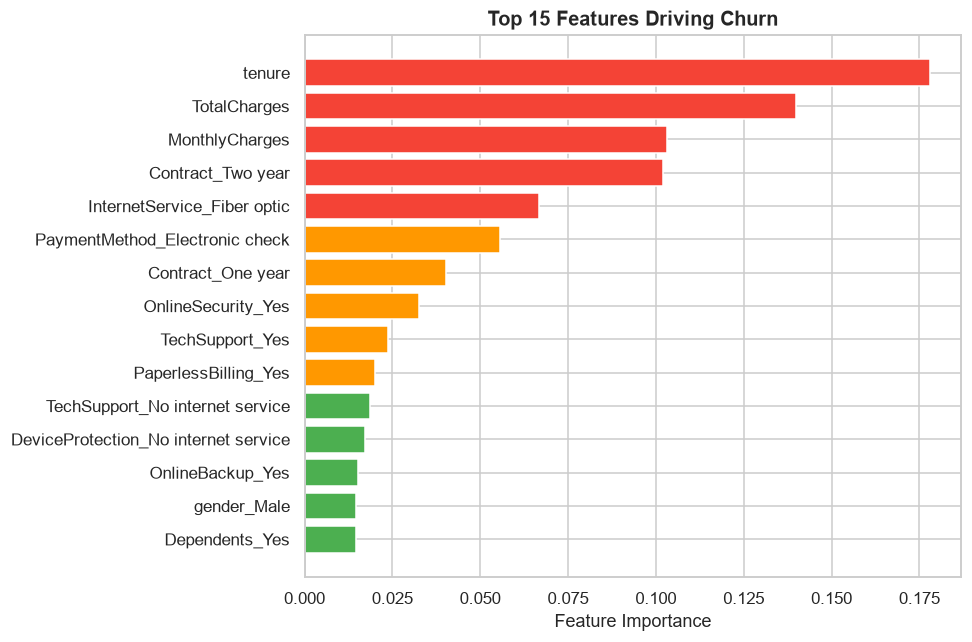

In [20]:
# Extract feature names after one-hot encoding
cat_feature_names = best_pipe.named_steps['pre']\
    .named_transformers_['cat'].get_feature_names_out(cat_cols).tolist()
all_features = num_cols + cat_feature_names

rf_model = best_pipe.named_steps['clf']
imp      = pd.Series(rf_model.feature_importances_, index=all_features)
top15    = imp.sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
colors_fi = ['#F44336' if i < 5 else '#FF9800' if i < 10 else '#4CAF50'
             for i in range(len(top15))]
plt.barh(top15.index[::-1], top15.values[::-1], color=colors_fi[::-1], edgecolor='white')
plt.xlabel('Feature Importance')
plt.title('Top 15 Features Driving Churn', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Save Model Artefacts

In [21]:
os.makedirs('model', exist_ok=True)

joblib.dump(best_pipe,       'model/churn_pipeline.pkl')
joblib.dump(num_cols,        'model/num_cols.pkl')
joblib.dump(cat_cols,        'model/cat_cols.pkl')

print('Saved model artefacts:')
for f in sorted(os.listdir('model')):
    size = os.path.getsize(f'model/{f}')/1024
    print(f'  model/{f}  ({size:.1f} KB)')

final_recall = recall_score(y_test, y_pred_tuned)
print(f'\nFinal model Recall (Churn): {final_recall:.2%}')

Saved model artefacts:
  model/cat_cols.pkl  (0.2 KB)
  model/churn_pipeline.pkl  (11309.6 KB)
  model/num_cols.pkl  (0.1 KB)

Final model Recall (Churn): 77.54%
